# Лабораторная работа №2. Интерпретация моделей

**Датасет:** [Walmart Dataset (Kaggle)](https://www.kaggle.com/datasets/yasserh/walmart-dataset) — подготовленный в лабораторной работе №1.

### Задачи
1. Обучить по датасету из лабораторной работы №1 модели XGBoost и Random Forest.
2. Получить важность признаков (feature importance).
3. Применить метод SHAP и проанализировать его результаты.

**Целевая переменная** — `Weekly_Sales`.

## Импорт библиотек

In [7]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, root_mean_squared_error, r2_score
from sklearn.preprocessing import RobustScaler
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.3f}'.format)
sns.set_theme(style='whitegrid')

RANDOM_STATE = 42

## Подготовка данных

Повторяем все шаги лабораторной работы №1 без промежуточного анализа:
1. замена шумового значения продаж магазина 18 за 02.09.2011 оценкой по соседним неделям;
2. согласование типов (`Store` → `category`, `Date` → `datetime`, `Holiday_Flag` → `bool`);
3. признаки даты, циклические признаки, индикаторы праздничного сезона;
4. лаги продаж за 1–4 недели и скользящие агрегации;
5. удаление строк с пропусками, появившимися из-за лагов;
6. робастное масштабирование числовых признаков;
7. one-hot кодирование `Store`.

In [8]:
df = pd.read_csv('data/Walmart.csv')

sales = (df.assign(Date=pd.to_datetime(df['Date'], format='%d-%m-%Y'))
           .pivot(index='Date', columns='Store', values='Weekly_Sales'))
for store, date in [(18, '02-09-2011')]:
    i = sales.index.get_loc(pd.to_datetime(date, format='%d-%m-%Y'))
    next5 = sales.iloc[i + 1:i + 6].mean()
    market = (sales.iloc[i] / next5).drop(store).median()
    df.loc[(df['Store'] == store) & (df['Date'] == date), 'Weekly_Sales'] = next5[store] * market

df['Store'] = df['Store'].astype('category')
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')
df['Holiday_Flag'] = df['Holiday_Flag'].astype(bool)

df = df.sort_values(['Store', 'Date']).reset_index(drop=True)
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Quarter'] = df['Date'].dt.quarter
df['WeekOfYear'] = df['Date'].dt.isocalendar().week.astype(int)
df['DayOfMonth'] = df['Date'].dt.day

df['Month_sin'] = np.sin(2 * np.pi * df['Month'] / 12)
df['Month_cos'] = np.cos(2 * np.pi * df['Month'] / 12)
df['Week_sin'] = np.sin(2 * np.pi * df['WeekOfYear'] / 52)
df['Week_cos'] = np.cos(2 * np.pi * df['WeekOfYear'] / 52)

def days_to(holiday, dates):
    return (dates.dt.year.map(holiday) - dates).dt.days

def black_friday(year):
    nov1 = pd.Timestamp(year, 11, 1)
    thanksgiving = nov1 + pd.Timedelta(days=(3 - nov1.weekday()) % 7 + 21)
    return thanksgiving + pd.Timedelta(days=1)

to_christmas = days_to(lambda y: pd.Timestamp(y, 12, 25), df['Date'])
from_black_friday = -days_to(black_friday, df['Date'])
df['Is_HolidaySeason'] = ((from_black_friday >= 0) & (to_christmas >= 1)).astype(int)
df['Is_PreChristmas'] = to_christmas.between(1, 7).astype(int)

lags = [1, 2, 3, 4]
for lag in lags:
    df[f'Sales_lag_{lag}'] = df.groupby('Store', observed=True)['Weekly_Sales'].shift(lag)
lag_features = [f'Sales_lag_{lag}' for lag in lags]

past_sales = df.groupby('Store', observed=True)['Weekly_Sales'].shift(1)
by_store = past_sales.groupby(df['Store'], observed=True)
df['Sales_roll_std_4'] = by_store.transform(lambda s: s.rolling(4).std())
df['Sales_roll_mean_12'] = by_store.transform(lambda s: s.rolling(12, min_periods=4).mean())
agg_features = ['Sales_roll_std_4', 'Sales_roll_mean_12']

df = df.dropna(subset=lag_features + agg_features).reset_index(drop=True)

scale_features = (['Temperature', 'Fuel_Price', 'CPI', 'Unemployment']
                  + lag_features + agg_features
                  + ['Year', 'Month', 'Quarter', 'WeekOfYear', 'DayOfMonth'])
scaler = RobustScaler()
df_scaled = df.copy()
df_scaled[scale_features] = scaler.fit_transform(df[scale_features])

df_encoded = df_scaled.copy()
df_encoded['Holiday_Flag'] = df_encoded['Holiday_Flag'].astype(int)
df_encoded = pd.get_dummies(df_encoded, columns=['Store'], prefix='Store', drop_first=True, dtype=int)

print(f'Размер датасета: {df_encoded.shape[0]} строк, {df_encoded.shape[1]} столбцов')
df_encoded.head(3)

Размер датасета: 6255 строк, 68 столбцов


,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Year,Month,Quarter,WeekOfYear,DayOfMonth,Month_sin,Month_cos,Week_sin,Week_cos,Is_HolidaySeason,Is_PreChristmas,Sales_lag_1,Sales_lag_2,Sales_lag_3,Sales_lag_4,Sales_roll_std_4,Sales_roll_mean_12,Store_2,Store_3,Store_4,Store_5,Store_6,Store_7,Store_8,Store_9,Store_10,Store_11,Store_12,Store_13,Store_14,Store_15,Store_16,Store_17,Store_18,Store_19,Store_20,Store_21,Store_22,Store_23,Store_24,Store_25,Store_26,Store_27,Store_28,Store_29,Store_30,Store_31,Store_32,Store_33,Store_34,Store_35,Store_36,Store_37,Store_38,Store_39,Store_40,Store_41,Store_42,Store_43,Store_44,Store_45
0,2010-03-05,1554806.680,0,-0.634,-1.089,0.354,0.141,-0.500,-0.800,-2.000,-0.739,-0.733,1.000,0.000,0.885,0.465,0,0,0.521,0.753,0.786,0.788,1.119,0.695,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,2010-03-12,1439541.590,0,-0.211,-1.035,0.354,0.141,-0.500,-0.800,-2.000,-0.696,-0.267,1.000,0.000,0.935,0.355,0,0,0.689,0.519,0.751,0.786,0.964,0.690,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,2010-03-19,1472515.790,0,-0.332,-0.967,0.352,0.141,-0.500,-0.800,-2.000,-0.652,0.200,1.000,0.000,0.971,0.239,0,0,0.556,0.687,0.518,0.751,0.833,0.665,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## Разбиение на обучающую и тестовую выборки

Данные — временные ряды, поэтому случайное разбиение недопустимо. первые 80% недель — обучение, последние 20% — тест.

In [9]:
target = 'Weekly_Sales'
X = df_encoded.drop(columns=['Date', target])
y = df_encoded[target]

dates = np.sort(df_encoded['Date'].unique())
split_date = dates[int(len(dates) * 0.8)]
train = df_encoded['Date'] < split_date

X_train, X_test = X[train], X[~train]
y_train, y_test = y[train], y[~train]

print(f'Обучение: {df_encoded.loc[train, "Date"].min().date()} — {df_encoded.loc[train, "Date"].max().date()}, {len(X_train)} строк')
print(f'Тест:     {df_encoded.loc[~train, "Date"].min().date()} — {df_encoded.loc[~train, "Date"].max().date()}, {len(X_test)} строк')

Обучение: 2010-03-05 — 2012-04-13, 4995 строк
Тест:     2012-04-20 — 2012-10-26, 1260 строк




Для интерпретации понадобятся значения признаков **в исходных единицах** (градусы, доллары, номер недели), а не после масштабирования.

In [10]:
X_display = X.copy()
X_display[scale_features] = df[scale_features]
X_test_display = X_display[~train]
X_test_display[scale_features].head(3)

,Temperature,Fuel_Price,CPI,Unemployment,Sales_lag_1,Sales_lag_2,Sales_lag_3,Sales_lag_4,Sales_roll_std_4,Sales_roll_mean_12,Year,Month,Quarter,WeekOfYear,DayOfMonth
111,66.760,3.877,221.564,7.143,1621031.700,1899676.880,1649604.630,1511068.070,164138.373,1653342.207,2012,4,2,16,20
112,67.230,3.814,221.618,7.143,1521577.870,1621031.700,1899676.880,1649604.630,160788.799,1670196.563,2012,4,2,17,27
113,75.550,3.749,221.672,7.143,1468928.370,1521577.870,1621031.700,1899676.880,191908.123,1656245.623,2012,5,2,18,4


## Обучение моделей

### Базовый прогноз

Чтобы понимать, насколько модели полезны, сравним их с наивным прогнозом: продажи на этой неделе равны продажам на прошлой (`Sales_lag_1`).

In [11]:
def metrics(y_true, y_pred):
    return {'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': root_mean_squared_error(y_true, y_pred),
            'MAPE, %': mean_absolute_percentage_error(y_true, y_pred) * 100}


naive_pred = df.loc[~train, 'Sales_lag_1']
results = {'Наивный (lag 1)': metrics(y_test, naive_pred)}
pd.DataFrame(results).T

,MAE,RMSE,"MAPE, %"
Наивный (lag 1),50734.820,75599.303,4.934


### Random Forest

Ансамбль глубоких деревьев, каждое из которых обучается на бутстреп-выборке и случайном подмножестве признаков; прогноз — среднее по деревьям.

- `n_estimators=200` — число деревьев;
- `min_samples_leaf=2` — минимум объектов в листе, ограничивает переобучение;
- `max_features=0.5` — каждое разбиение выбирается среди половины признаков.

In [12]:
rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=2, max_features=0.5,
                           n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
results['Random Forest'] = metrics(y_test, rf_pred)

### XGBoost

Градиентный бустинг: деревья строятся последовательно, каждое следующее исправляет ошибки предыдущих.

- `n_estimators=1000`, `learning_rate=0.03` — много деревьев с маленьким шагом обучения;
- `max_depth=6` — глубина деревьев;
- `subsample=0.8`, `colsample_bytree=0.8` — каждое дерево обучается на 80% строк и 80% признаков, это регуляризация.

In [13]:
xgb = XGBRegressor(n_estimators=1000, learning_rate=0.03, max_depth=6,
                   subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE)
xgb.fit(X_train, y_train)

xgb_pred = xgb.predict(X_test)
results['XGBoost'] = metrics(y_test, xgb_pred)

### Сравнение качества

In [14]:
pd.DataFrame(results).T.style.format({'MAE': '{:,.0f}', 'RMSE': '{:,.0f}', 'MAPE, %': '{:.2f}'})

,MAE,RMSE,"MAPE, %"
Наивный (lag 1),"50,735","75,599",4.93
Random Forest,"37,052","53,782",3.66
XGBoost,"37,411","53,064",3.88


Сравним прогнозы с фактом на тестовом периоде для нескольких магазинов разного размера:

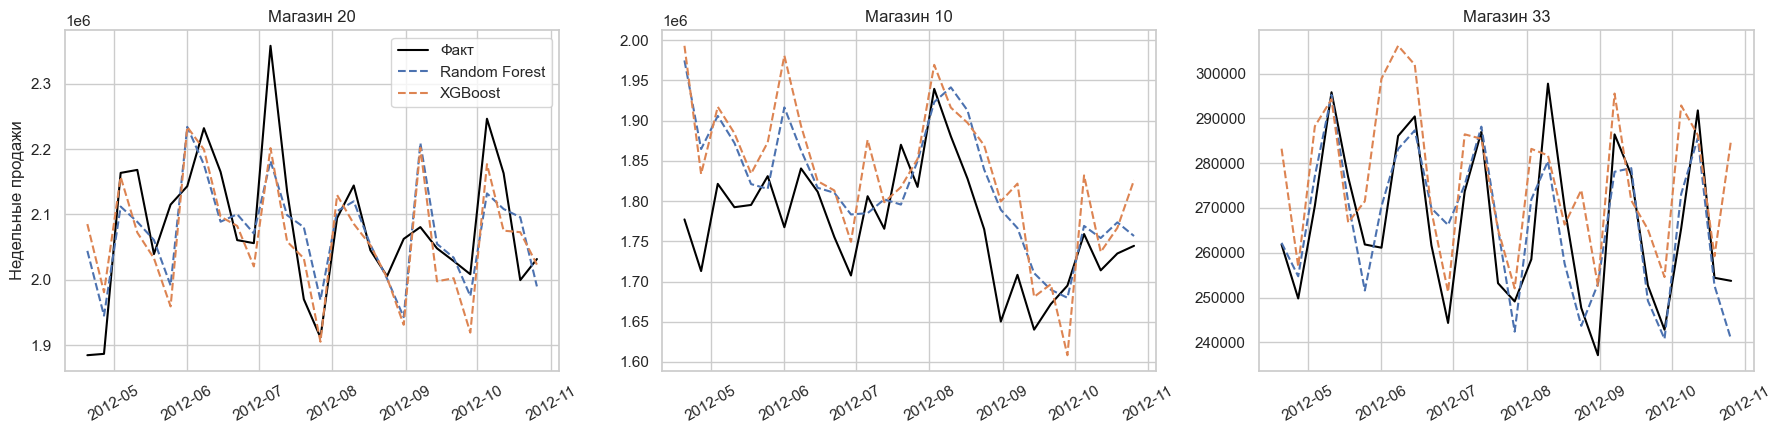

In [15]:
test = df.loc[~train, ['Store', 'Date', 'Weekly_Sales']].assign(RF=rf_pred, XGB=xgb_pred)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, store in zip(axes, [20, 10, 33]):
    part = test[test['Store'] == store]
    ax.plot(part['Date'], part['Weekly_Sales'], color='black', label='Факт')
    ax.plot(part['Date'], part['RF'], ls='--', label='Random Forest')
    ax.plot(part['Date'], part['XGB'], ls='--', label='XGBoost')
    ax.set_title(f'Магазин {store}')
    ax.tick_params(axis='x', rotation=30)
axes[0].set_ylabel('Недельные продажи')
axes[0].legend()
plt.tight_layout()
plt.show()

**Вывод.** Обе модели заметно точнее наивного прогноза.

## Важность признаков (feature importance)

### Встроенная важность

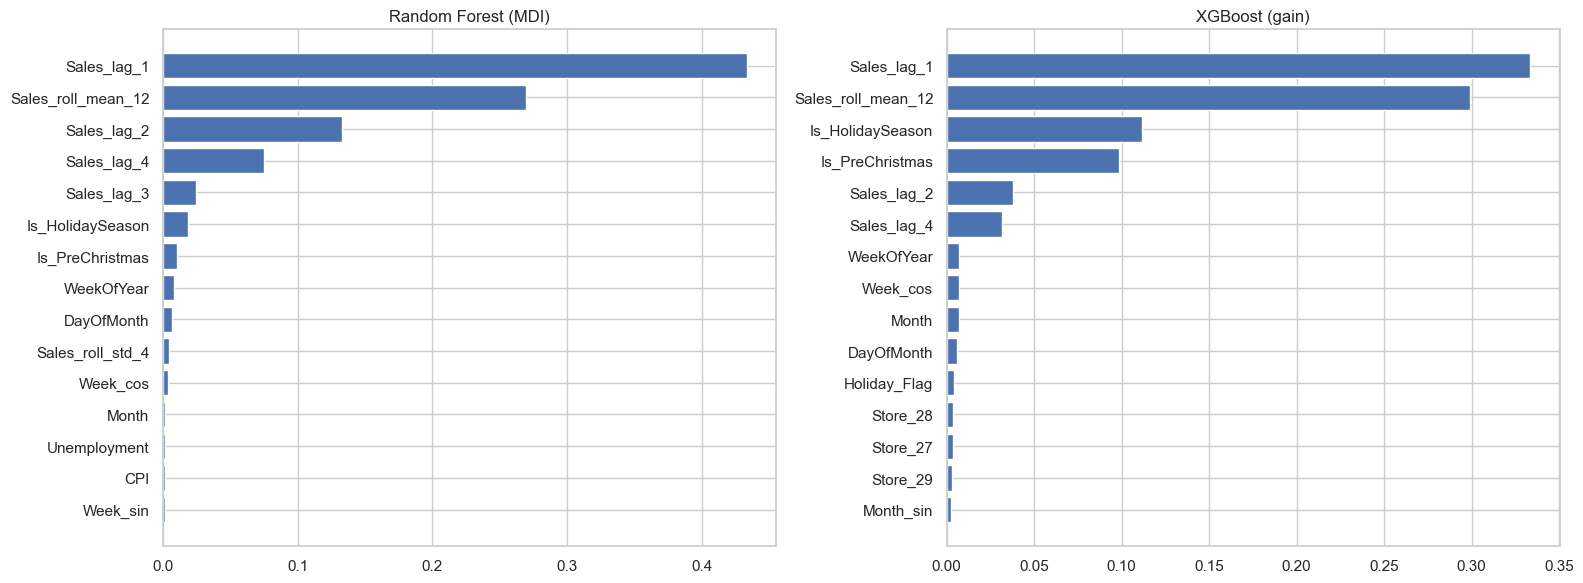

In [16]:
importance = pd.DataFrame({'Random Forest (MDI)': rf.feature_importances_,
                           'XGBoost (gain)': xgb.feature_importances_}, index=X.columns)


def plot_importance(imp, title, top=15, ax=None):
    imp = imp.sort_values(ascending=False).head(top)[::-1]
    ax = ax or plt.gca()
    ax.barh(imp.index, imp.values)
    ax.set_title(title)


fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, col in zip(axes, importance.columns):
    plot_importance(importance[col], col, ax=ax)
plt.tight_layout()
plt.show()

### Перестановочная важность (permutation importance)


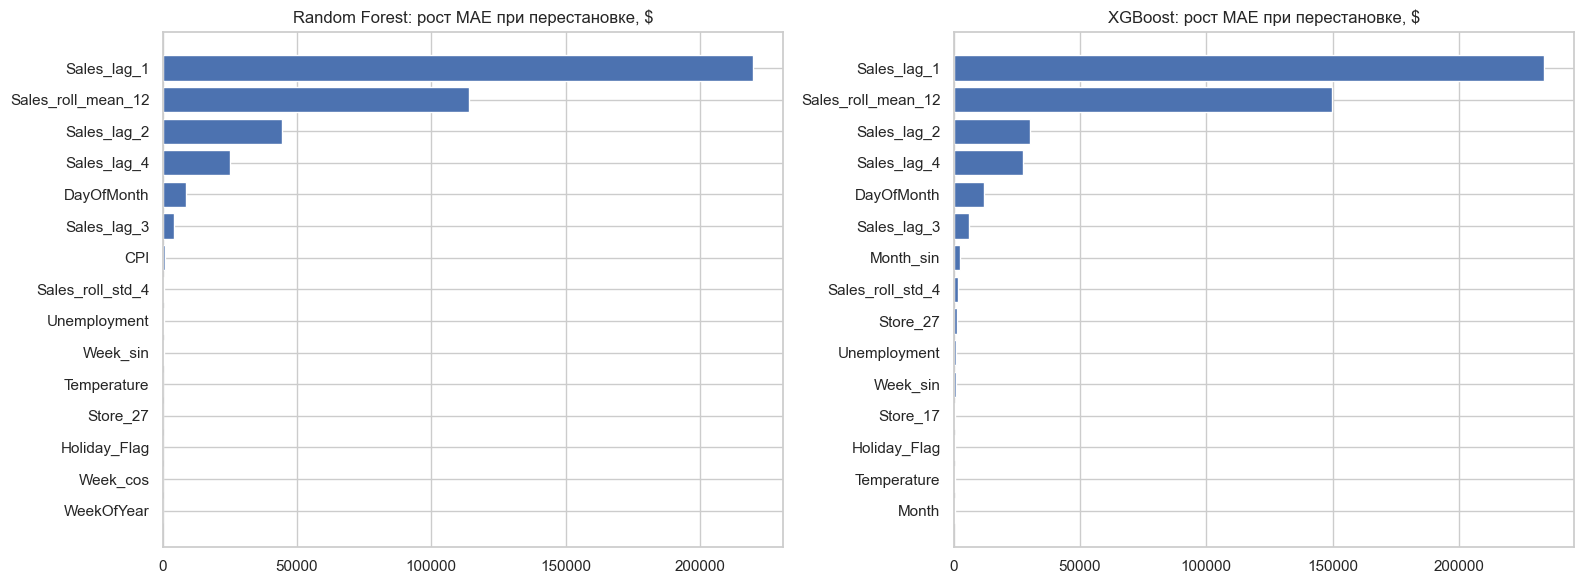

In [18]:
perm = {}
for name, model in [('Random Forest', rf), ('XGBoost', xgb)]:
    result = permutation_importance(model, X_test, y_test, scoring='neg_mean_absolute_error',
                                    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
    perm[name] = pd.Series(result.importances_mean, index=X.columns)
perm = pd.DataFrame(perm)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, col in zip(axes, perm.columns):
    plot_importance(perm[col], f'{col}: рост MAE при перестановке, $', ax=ax)
plt.tight_layout()
plt.show()

### Сравнение оценок важности

Сведём все оценки в одну таблицу. Чтобы их можно было сравнивать, переведём каждую в ранг (1 — самый важный признак).

In [19]:
all_importance = pd.concat([importance, xgb_types[['weight']].rename(columns={'weight': 'XGBoost (weight)'}),
                            perm.add_prefix('Перестановочная: ')], axis=1)
ranks = all_importance.rank(ascending=False).astype(int)
top = ranks.min(axis=1).sort_values().index[:15]
ranks.loc[top].sort_values('Перестановочная: XGBoost')

,Random Forest (MDI),XGBoost (gain),XGBoost (weight),Перестановочная: Random Forest,Перестановочная: XGBoost
Sales_lag_1,1,1,4,1,1
Sales_roll_mean_12,2,2,11,2,2
Sales_lag_2,3,5,8,3,3
Sales_lag_4,4,6,7,4,4
DayOfMonth,9,10,2,5,5
Sales_lag_3,5,16,9,6,6
Month_sin,22,15,17,16,7
Sales_roll_std_4,10,29,5,8,8
Temperature,16,44,1,11,14
CPI,14,35,6,7,16


## SHAP

Для деревьев используем `TreeExplainer` — он вычисляет точные значения Шепли за полиномиальное время, используя структуру деревьев. Объясняем прогнозы на тестовой выборке.

In [11]:
%%time
rf_explainer = shap.TreeExplainer(rf)
xgb_explainer = shap.TreeExplainer(xgb)

rf_shap = rf_explainer(X_test)
xgb_shap = xgb_explainer(X_test)

rf_shap.data = X_test_display.values
xgb_shap.data = X_test_display.values

CPU times: user 1min 7s, sys: 399 ms, total: 1min 8s
Wall time: 1min 5s




### Глобальная важность

Важность признака — средний модуль его вклада по всем объектам: на сколько долларов в среднем признак сдвигает прогноз.

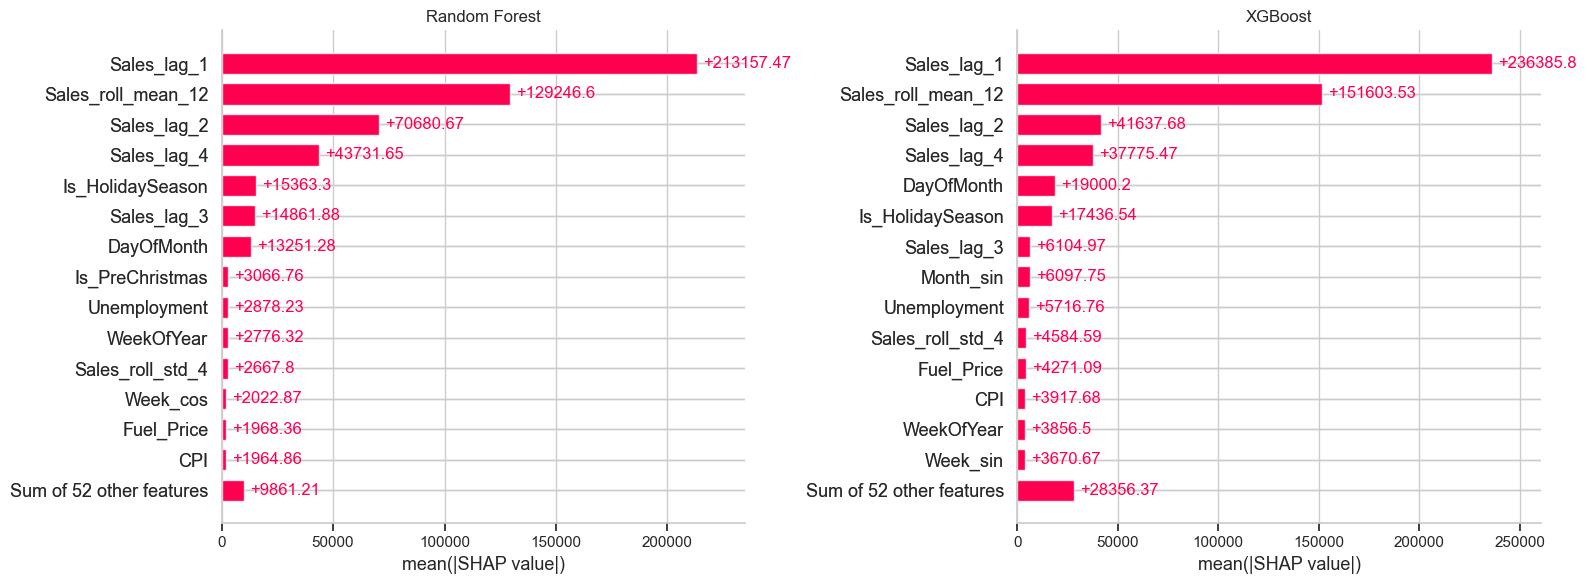

In [12]:
fig = plt.figure(figsize=(16, 6))
for i, (name, sv) in enumerate([('Random Forest', rf_shap), ('XGBoost', xgb_shap)], start=1):
    ax = fig.add_subplot(1, 2, i)
    shap.plots.bar(sv, max_display=15, ax=ax, show=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

Признак `Store` разбит one-hot кодированием на 44 столбца, и вклад каждого по отдельности мал. Благодаря аддитивности SHAP-значения можно **сложить** по группе столбцов и получить вклад исходного признака «магазин» целиком.

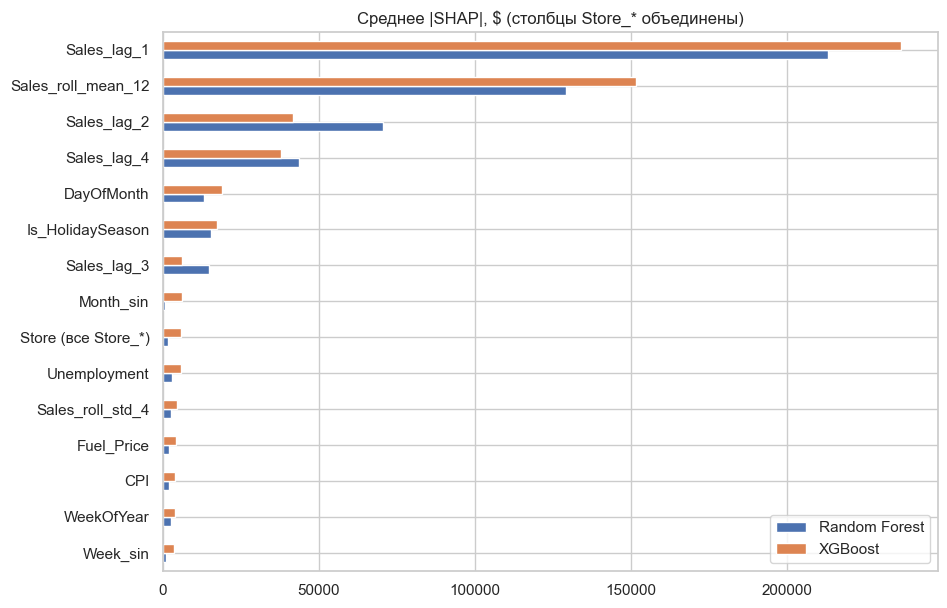

,Random Forest,XGBoost
Sales_lag_1,"213,157","236,386"
Sales_roll_mean_12,"129,247","151,604"
Sales_lag_2,"70,681","41,638"
Sales_lag_4,"43,732","37,775"
DayOfMonth,"13,251","19,000"
Is_HolidaySeason,"15,363","17,437"
Sales_lag_3,"14,862","6,105"
Month_sin,854,"6,098"
Store (все Store_*),"1,722","5,773"
Unemployment,"2,878","5,717"


In [13]:
store_cols = [col for col in X.columns if col.startswith('Store_')]


def grouped_shap(sv):
    values = pd.DataFrame(sv.values, columns=X.columns)
    values['Store (все Store_*)'] = values[store_cols].sum(axis=1)
    return values.drop(columns=store_cols).abs().mean()


shap_importance = pd.DataFrame({'Random Forest': grouped_shap(rf_shap),
                                'XGBoost': grouped_shap(xgb_shap)})
shap_importance = shap_importance.sort_values('XGBoost', ascending=False)

ax = shap_importance.head(15)[::-1].plot.barh(figsize=(10, 7))
ax.set_title('Среднее |SHAP|, $ (столбцы Store_* объединены)')
plt.show()

shap_importance.head(15).style.format('{:,.0f}')

**Вывод.**
- Обе модели объясняются одинаково: порядок признаков по SHAP почти совпадает.
- Главный признак — `Sales_lag_1`: в среднем сдвигает прогноз на ~200 тыс. $ относительно базового значения. Далее `Sales_roll_mean_12`, `Sales_lag_2`, `Sales_lag_4`. Вместе они определяют, **насколько большой магазин** — основной источник различий в продажах.

### Распределение вкладов: beeswarm

Каждая точка — один объект тестовой выборки. По горизонтали — SHAP-значение (вклад в прогноз), цвет — значение признака (красный — большое, синий — маленькое).

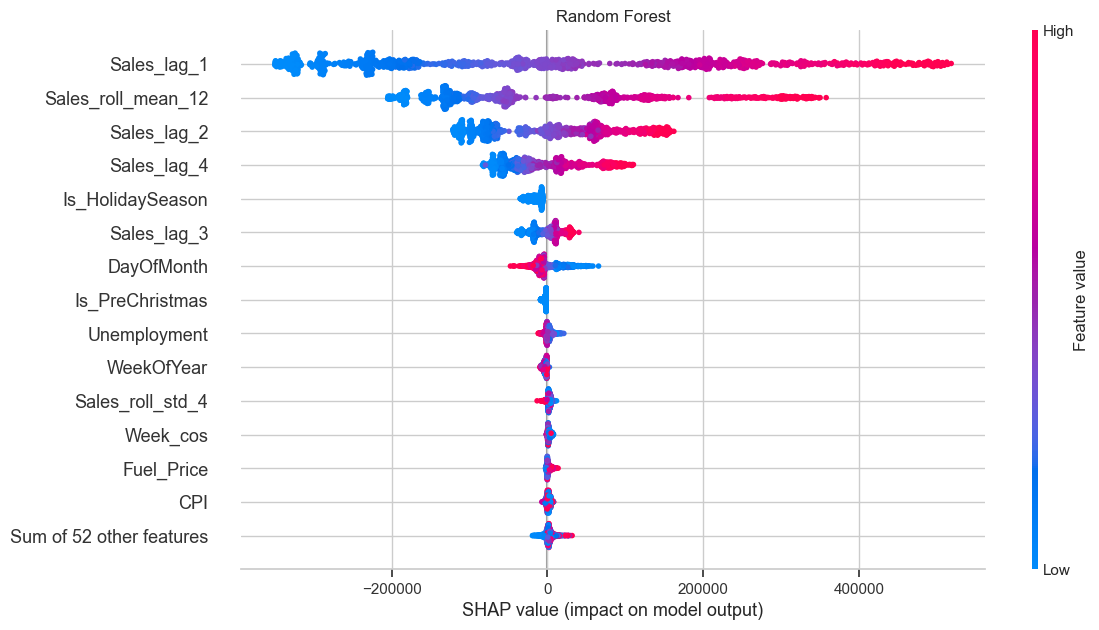

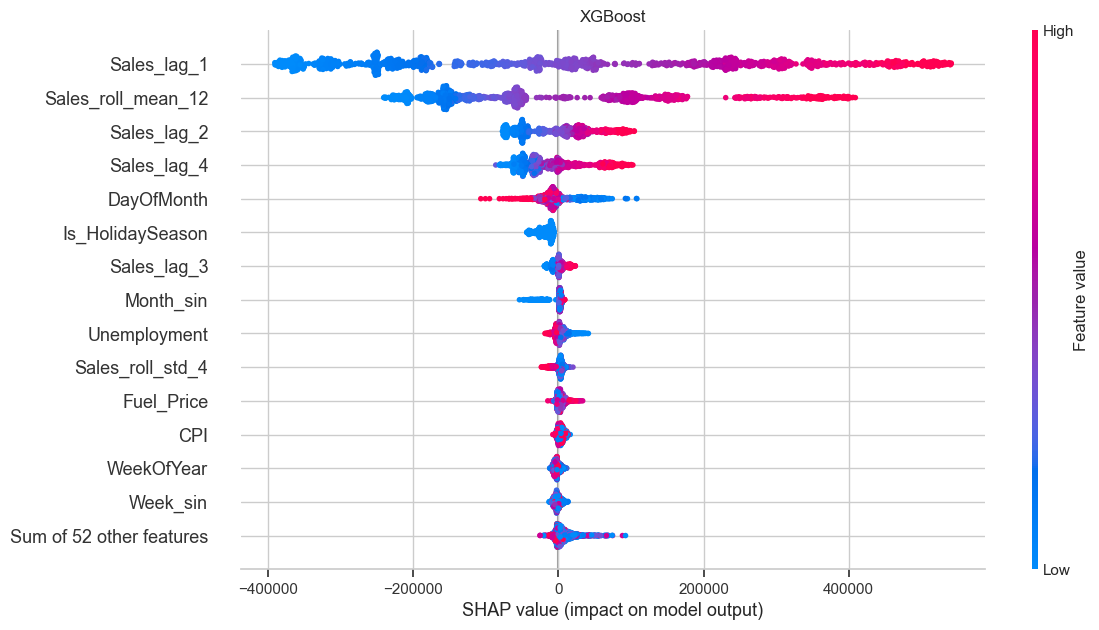

In [14]:
for name, sv in [('Random Forest', rf_shap), ('XGBoost', xgb_shap)]:
    plt.figure()
    shap.plots.beeswarm(sv, max_display=15, show=False, plot_size=(12, 7))
    plt.title(name)
    plt.show()


### Локальные объяснения: waterfall

Waterfall-график раскладывает **один** прогноз: от базового значения $\phi_0$ каждый признак сдвигает прогноз вверх или вниз, пока не получится итоговое значение $f(x)$.

**Пример 1.** Неделя перед Рождеством 2011 года в крупном магазине 20.

Магазин 20, 2011-12-23: факт 3,555,371 $, прогноз 3,564,113 $


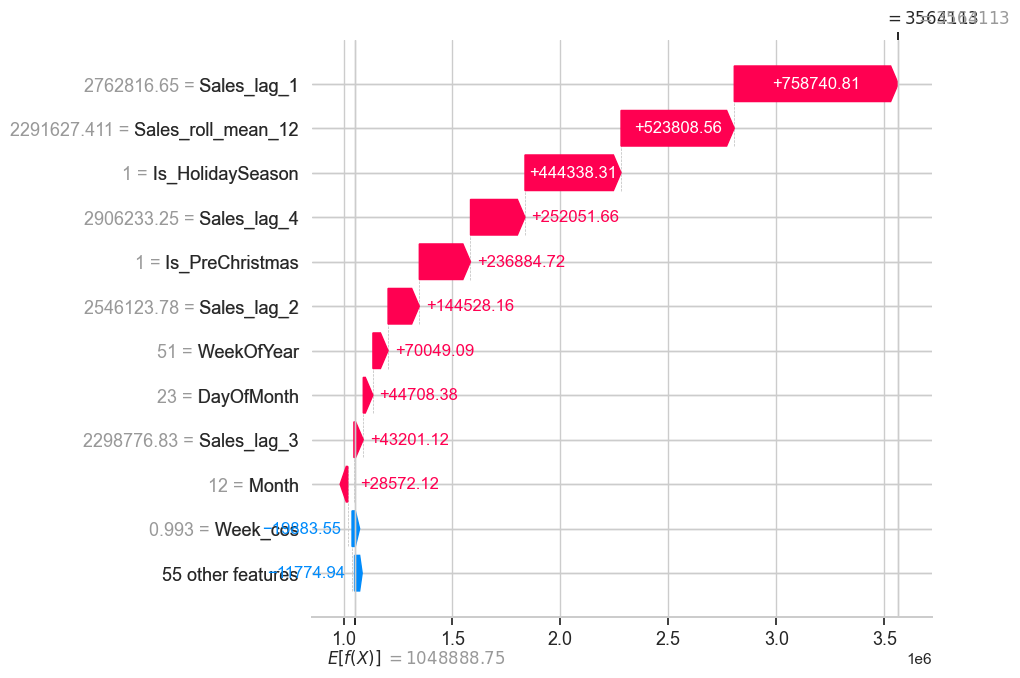

In [16]:
def explain_row(store, date, sv, rows):
    i = np.flatnonzero((df.loc[rows, 'Store'] == store).values & (df.loc[rows, 'Date'] == date).values)[0]
    fact = df.loc[rows, 'Weekly_Sales'].iloc[i]
    pred = sv.base_values[i] + sv.values[i].sum()
    print(f'Магазин {store}, {pd.Timestamp(date).date()}: факт {fact:,.0f} $, прогноз {pred:,.0f} $')
    shap.plots.waterfall(sv[i], max_display=12)


xgb_shap_all = xgb_explainer(X)
xgb_shap_all.data = X_display.values

explain_row(20, '2011-12-23', xgb_shap_all, df.index)

Прогноз намного выше базового значения. Основной вклад дают лаги и праздничные индикаторы `Is_PreChristmas` и `Is_HolidaySeason`.

**Пример 2.** Обычная неделя небольшого магазина 33 на тестовом периоде.

Магазин 33, 2012-07-13: факт 287,034 $, прогноз 285,446 $


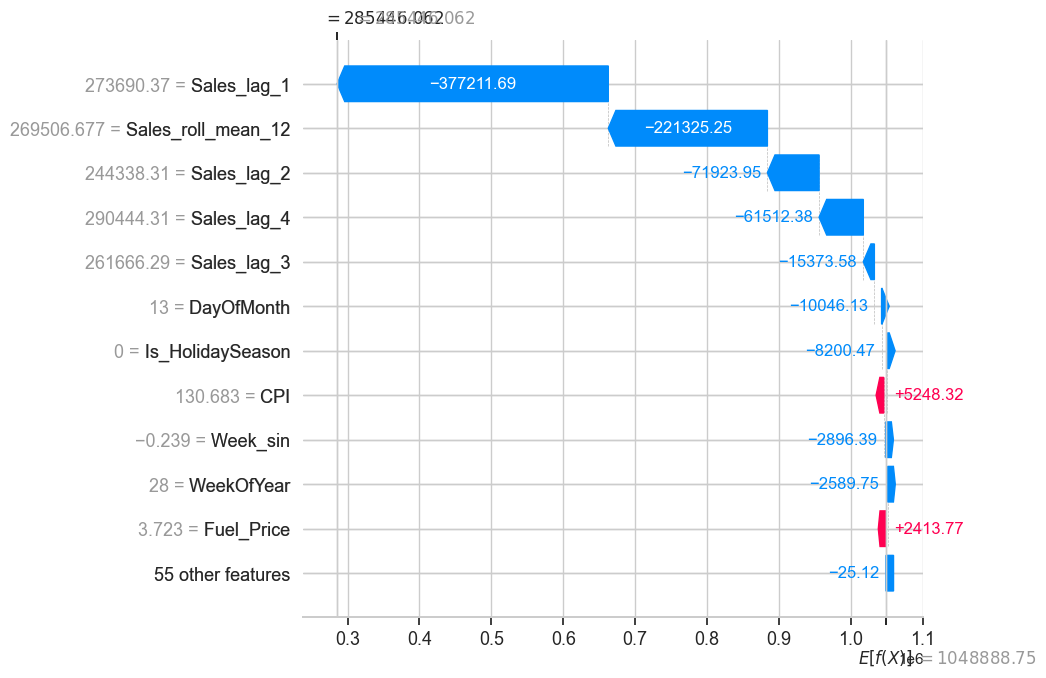

In [17]:
explain_row(33, '2012-07-13', xgb_shap, ~train)

Здесь лаги и скользящее среднее тянут прогноз далеко **вниз** от базового значения — магазин маленький. `Is_HolidaySeason = 0` дополнительно немного снижает прогноз.

**Пример 3.** Объект с наибольшей ошибкой XGBoost на тесте — посмотрим, почему модель ошиблась.

Ошибка: 354,929 $ (21.4 %)
Магазин 14, 2012-06-22: факт 1,660,229 $, прогноз 2,015,156 $


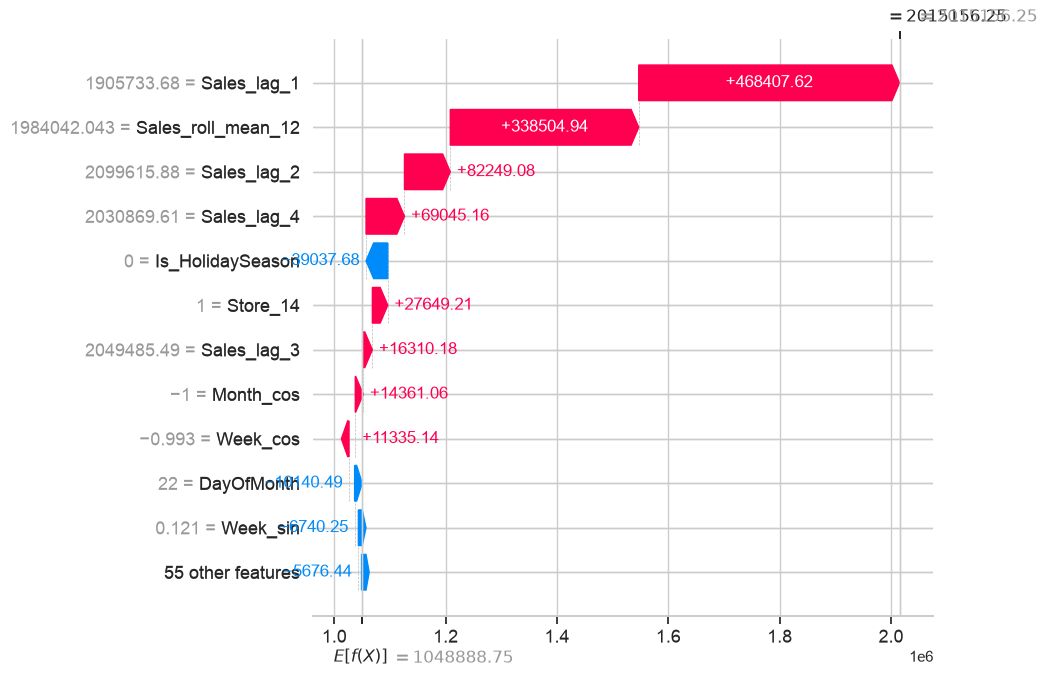

Date,2012-05-25,2012-06-01,2012-06-08,2012-06-15,2012-06-22,2012-06-29,2012-07-06
Weekly_Sales,2030869.610,2049485.490,2099615.880,1905733.680,1660228.880,1591835.020,1862128.950


In [23]:
errors = test.assign(Error=test['XGB'] - test['Weekly_Sales'])
worst = errors.loc[errors['Error'].abs().idxmax()]
print(f'Ошибка: {worst["Error"]:,.0f} $ ({worst["Error"] / worst["Weekly_Sales"] * 100:.1f} %)')

explain_row(worst['Store'], worst['Date'], xgb_shap, ~train)
df.loc[df['Store'] == worst['Store'], ['Date', 'Weekly_Sales']].set_index('Date').loc[
    worst['Date'] - pd.Timedelta(weeks=4):worst['Date'] + pd.Timedelta(weeks=2)].T

Модель опирается на продажи прошлых недель, поэтому резкие изменения, которых не было в лагах, она предсказывает плохо. SHAP показывает, на что именно опиралась модель, и помогает понять причину ошибки.

## Итоги

**Модели.** Random Forest и XGBoost, обученные на датасете из лабораторной работы №1, показывают близкое качество и заметно точнее наивного прогноза по прошлой неделе.

**SHAP.**
- Даёт важность в долларах продаж, показывает направление влияния и объясняет каждый прогноз отдельно; аддитивность позволяет объединять вклады one-hot столбцов.
- Продажи определяются прежде всего **уровнем продаж магазина** в прошлые недели (лаги и скользящее среднее) — зависимость монотонная, почти линейная.
- **Праздничный сезон и неделя перед Рождеством** дают большую надбавку к прогнозу, пропорциональную размеру магазина. Признаки `Is_HolidaySeason` и `Is_PreChristmas`, созданные в лабораторной работе №1, полезнее исходного `Holiday_Flag`.
- **Безработица** снижает продажи монотонно, но слабо; **температура, цена топлива и CPI** почти не влияют. Номер магазина отдельно от лагов тоже почти не важен.
- Обе модели объясняются одинаково — выученные закономерности устойчивы и не зависят от алгоритма.